# Лабораторная работа 1. Двумерный калий с периодическими границами

**Цель:** смоделировать движение одноатомного газа калия в двумерной коробке и проверить поведение энергии, температуры и давления в ансамбле NVE.

**Система:** 1035 атомов K, коробка $24\times24$ нм, заданная температура $900\,^{\circ}\mathrm C=1173.15$ K, периодические условия по x и y.

**Ожидаемый результат:** траектория и графики наблюдаемых величин; малая относительная ошибка полной энергии при разумном шаге интегрирования. Давление равновесия будет оцениваться отдельно в работе 02.

**Студент:** ____________________  **Группа:** __________  **Преподаватель:** ____________________

> Перед запуском выберите `DEMO` или `FULL` в первой конфигурационной ячейке. DEMO сохраняет полное число частиц, но сокращает траекторию; он не заменяет производственный расчёт. Подробная инструкция — `notebooks/README.md`.

## 1. Постановка задачи и проверка результата

Нужно получить микроскопическую траекторию атомов, вычисляя силы из парного потенциала и перемещая частицы по закону Ньютона. Периодические границы имитируют повторяющиеся ячейки вещества и не дают частицам искусственно ударяться о край коробки.

Корректность проверяем по четырём признакам: (1) координаты остаются в коробке после периодического заворачивания; (2) пары на противоположных гранях взаимодействуют по кратчайшему minimum-image расстоянию; (3) полная энергия NVE не имеет систематического дрейфа, превышающего численный допуск; (4) температура и давление флуктуируют как мгновенные величины, а не насильно удерживаются на одном значении. Периодическая картинка сама по себе не доказывает равновесие.

## 2. Теория и исходные данные

Сила на частицу $i$ равна $\mathbf F_i=-\nabla_i U$. Для пары используется LJTS из введения: LJ-потенциал с вычтенным значением в $r_c=2.5\sigma$ и нулём за cutoff. Сдвиг делает энергию непрерывной, но производная (и сила) в cutoff может быть разрывной. При $\mathbf r_{ij}=\mathbf r_i-\mathbf r_j$ модуль расстояния вычисляется с minimum image; сила пары на второй атом противоположна силе на первом.

Для каждой компоненты скорости Maxwell–Boltzmann даёт дисперсию $k_BT/m$. В плоскости $2N$ степеней свободы; если скорость центра масс удалена, $f=2N-2$ и $T=2K/(f k_B)$. В NVE интегратор Velocity Verlet использует координатное обновление второго порядка, пересчитывает силу в новой точке и затем обновляет скорость.

Двумерное вириальное давление: $P_{2D}=(K+W/2)/A$, где $K$ — полная кинетическая энергия (Дж), $W=\sum_{i<j}\mathbf r_{ij}\cdot\mathbf F_{ij}$ — вириал пар (Дж), $A=L_xL_y$ — площадь (м²). Поэтому $P_{2D}$ имеет единицы Дж/м² = Н/м, а не Па. Условное эквивалентное 3D-давление — $P_{2D}/z$, если заранее оговорить эффективную толщину слоя $z$.

| Величина | Обозначение | Значение | Единица | Пояснение |
|---|---:|---:|---|---|
| Число частиц | $N$ | 1035 | 1 | Получено из концентрации 4 моль/л по процедуре задания, см. расчёт ниже |
| Температура | $T$ | 900 °C = 1173.15 | K | $T_K=T_{°C}+273.15$ |
| Размер коробки | $L_x,L_y$ | 24, 24 | nm | Площадь $5.76\cdot10^{-16}$ м² |
| Масса атома K | $m$ | 6.4924$\cdot10^{-26}$ | kg | 39.0983 u, IUPAC/CIAAW |
| Размер LJ | $\sigma$ | 0.4250 | nm | Фиксированное значение модели проекта |
| Глубина ямы | $\varepsilon/k_B$ | 850 | K | $\varepsilon=850k_B$ Дж на частицу/пару в парном потенциале |
| Обрезание | $r_c$ | $2.5\sigma$ | nm | Энергетически сдвинутый LJTS |
| Временной шаг | $\Delta t$ | 1 | fs | $1\,\mathrm{fs}=10^{-15}$ s |

Параметры K–K взяты из `src/constants.py`; в проекте отсутствует однозначная ссылка на источник именно пары $\sigma=0.4250$ нм, $\varepsilon/k_B=850$ K. Не следует выдавать её за точную универсальную параметризацию калия. Eslami, Mozaffari и Moghadasi (2010, DOI: [10.1007/bf03246015](https://doi.org/10.1007/bf03246015)) сравнивают LJ 12–6 с альтернативными потенциалами и обсуждают его ограничения для фазового поведения калия. Масса: [CIAAW atomic weights](https://ciaaw.org/atomic-weights.htm); точные $k_B$ и $N_A$: SI/BIPM.

**Как получено N.** При $C=4$ моль/л в 1 л имеется $N_{ref}=C V_{ref}N_A$ атомов. Толщина слоя выбрана как $z=(V_{ref}/N_{ref})^{1/3}$. В одном квадратном слое со стороной $V_{ref}^{1/3}=10$ см содержится $N_{layer}=N_{ref}z/V_{ref}^{1/3}$ частиц; перенос на площадь коробки даёт $N=N_{layer}A/(V_{ref}^{1/3})^2\approx1035.05$, округлённо 1035. Здесь объём и толщина задают лишь условный переход из 3D-концентрации к 2D-слою.

## 3. Подключение библиотек и выбор режима

В ячейке `import` подключает NumPy, Matplotlib и стандартные инструменты путей; `from ... import ...` делает доступными конкретные функции ядра `src`. `Path.cwd()` узнаёт текущую папку запуска, после чего мы ищем вверх по папкам корень с `pyproject.toml`. Это позволяет запускать notebook как из корня проекта, так и из `notebooks/`. `default_config()` возвращает объект настроек системы; именованные аргументы явно указывают начальное число, ускоренный список ячеек для сил и периодичность двух осей. Число шагов регулирует длину траектории, `sample_interval` — частоту сохранения физических величин, `frame_interval` — частоту кадров. `history` будет словарём массивов, а `frames` — массивом координат для анимации.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

# Ищем каталог проекта по признаку его конфигурационного файла.
search_paths = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(path for path in search_paths if (path / 'pyproject.toml').is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import default_config
from src.constants import BOLTZMANN, LAYER_THICKNESS, TEMPERATURE_K
from src.simulation import run_nve
from src.visualization import save_task1_animation

MODE = 'DEMO'  # Для полного расчёта замените строку на 'FULL' и выполните notebook заново.
if MODE == 'DEMO':
    N_STEPS, SAMPLE_EVERY, FRAME_EVERY = 300, 1, 10
elif MODE == 'FULL':
    N_STEPS, SAMPLE_EVERY, FRAME_EVERY = 50_000, 10, 500
else:
    raise ValueError("MODE должен быть 'DEMO' или 'FULL'")
SEED = 7
config = default_config(seed=SEED, force_backend='cell_list', periodic_x=True, periodic_y=True)
print(f'Режим {MODE}: N={config.n_particles}, шагов={N_STEPS}, dt={config.dt / 1e-15:.1f} фс, длительность={N_STEPS * config.dt * 1e12:.3f} пс, seed={SEED}')

Режим DEMO: N=1035, шагов=300, dt=1.0 фс, длительность=0.300 пс, seed=7


## 4. Выполнение траектории

`run_nve(config, ...)` создаёт объект-движок `MDEngine`, подготавливает координаты и скорости, затем повторяет Velocity Verlet указанное число раз. Параметр `sample_interval` задаёт, через сколько шагов добавлять наблюдения в историю; `frame_interval` управляет сохранением координат для движения частиц. Возвращаются два объекта: `history` — словарь NumPy-массивов (`step`, `time`, энергии, температура, давление), `frames` — координаты частиц для выбранных моментов. Сначала выводим несколько элементов словаря и размер массива кадров: это пример просмотра результата функции и проверки, что расчёт действительно выполнен.

In [2]:
history, frames = run_nve(config, n_steps=N_STEPS, sample_interval=SAMPLE_EVERY, frame_interval=FRAME_EVERY)
print('Ключи и количество наблюдений:', {name: len(values) for name, values in history.items()})
print('Размер массива кадров (кадр, частица, координата):', frames.shape)
print(f"Начальная T={history['temperature'][0]:.2f} K; конечная T={history['temperature'][-1]:.2f} K")

Ключи и количество наблюдений: {'step': 301, 'kinetic_energy': 301, 'potential_energy': 301, 'total_energy': 301, 'temperature': 301, 'pressure_2d': 301, 'time': 301}
Размер массива кадров (кадр, частица, координата): (31, 1035, 2)
Начальная T=1173.15 K; конечная T=1306.79 K


## 5. Графики и диагностика сохранения энергии

Следующая ячейка строит три панели: обмен кинетической и потенциальной энергией вместе с полной энергией; отклонение полной энергии от начального значения; температуру и 2D-давление во времени. Срез `history['...']` обращается к массиву по строковому ключу словаря. Энергии показаны в $10^{-18}$ Дж, чтобы числа было удобно читать. `np.max` находит наибольшее абсолютное относительное отклонение энергии. Идеальное газовое значение давления — только ориентир, оно не подгоняется к MD-данным и не учитывает вириальную поправку.

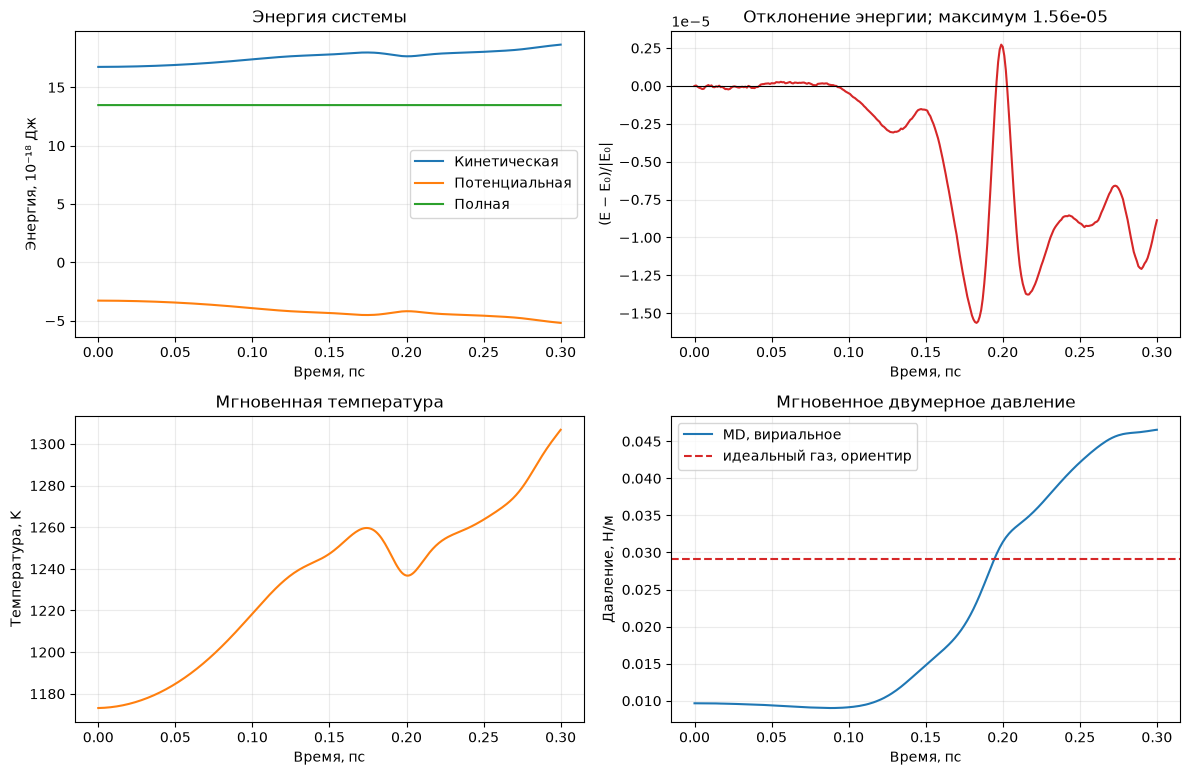

Максимальный относительный дрейф полной энергии: 1.5637e-05 (1.5637e-03 %)
Средняя T за сохранённую траекторию: 1233.044 K; это не автоматически равновесное значение
Среднее мгновенное P₂D за эту траекторию: 2.22257e-02 Н/м
Условный эквивалент 3D для среднего: 2.97938e+07 Па, при z=0.746 нм


In [3]:
time_ps = history['time'] * 1e12  # секунды переводим в пикосекунды
energy_scale = 1e18
initial_energy = history['total_energy'][0]
relative_drift = (history['total_energy'] - initial_energy) / abs(initial_energy)
ideal_pressure_2d = config.n_particles * BOLTZMANN * config.temperature / config.box.area
max_drift = float(np.max(np.abs(relative_drift)))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for key, label in [('kinetic_energy', 'Кинетическая'), ('potential_energy', 'Потенциальная'), ('total_energy', 'Полная')]:
    axes[0, 0].plot(time_ps, history[key] * energy_scale, label=label)
axes[0, 0].set(title='Энергия системы', xlabel='Время, пс', ylabel='Энергия, 10⁻¹⁸ Дж'); axes[0, 0].legend()
axes[0, 1].plot(time_ps, relative_drift, color='tab:red')
axes[0, 1].axhline(0, color='black', linewidth=0.8)
axes[0, 1].set(title=f'Отклонение энергии; максимум {max_drift:.2e}', xlabel='Время, пс', ylabel='(E − E₀)/|E₀|')
axes[1, 0].plot(time_ps, history['temperature'], color='tab:orange')
axes[1, 0].set(title='Мгновенная температура', xlabel='Время, пс', ylabel='Температура, K')
axes[1, 1].plot(time_ps, history['pressure_2d'], label='MD, вириальное')
axes[1, 1].axhline(ideal_pressure_2d, color='tab:red', linestyle='--', label='идеальный газ, ориентир')
axes[1, 1].set(title='Мгновенное двумерное давление', xlabel='Время, пс', ylabel='Давление, Н/м'); axes[1, 1].legend()
for axis in axes.flat: axis.grid(alpha=0.25)
fig.tight_layout(); plt.show()

print(f'Максимальный относительный дрейф полной энергии: {max_drift:.4e} ({100 * max_drift:.4e} %)')
print(f'Средняя T за сохранённую траекторию: {np.mean(history["temperature"]):.3f} K; это не автоматически равновесное значение')
print(f'Среднее мгновенное P₂D за эту траекторию: {np.mean(history["pressure_2d"]):.5e} Н/м')
print(f'Условный эквивалент 3D для среднего: {np.mean(history["pressure_2d"]) / LAYER_THICKNESS:.5e} Па, при z={LAYER_THICKNESS * 1e9:.3f} нм')

### Физическая интерпретация

В NVE температура не закреплена термостатом: система перераспределяет энергию между движением и взаимодействиями, поэтому кинетическая энергия, потенциальная энергия, температура и давление флуктуируют. Их средние могут сместиться после старта, если начальное размещение не было равновесной конфигурацией. Важная проверка интегратора — полная энергия $E=K+U$: для малых шагов Verlet обычно даёт ограниченные колебания около начального значения. Небольшой обратимый/осциллирующий дрейф не равен статистическому шуму; крупный монотонный дрейф указывал бы на слишком большой шаг или численную проблему.

Идеально-газовый ориентир $Nk_BT/A$ может отличаться от MD из-за взаимодействий и различия условий. Среднее в этой ячейке вычислено по всей сохранённой траектории, включая возможный переходный участок; его нельзя называть равновесным давлением без отдельной диагностики. Короткий DEMO показывает работу вычислительного процесса, но не позволяет заключать о равновесии.

## 6. Расположение частиц и сохранение результатов

Здесь строятся начальная и конечная конфигурации из `frames`. В NumPy-индексации `frames[0, :, 0]` означает x-координаты всех частиц первого кадра. `save_task1_animation` сохраняет GIF и не меняет траекторию. Функция `np.savetxt` экспортирует числовые столбцы CSV, а `Path` задаёт переносимый путь от корня репозитория.

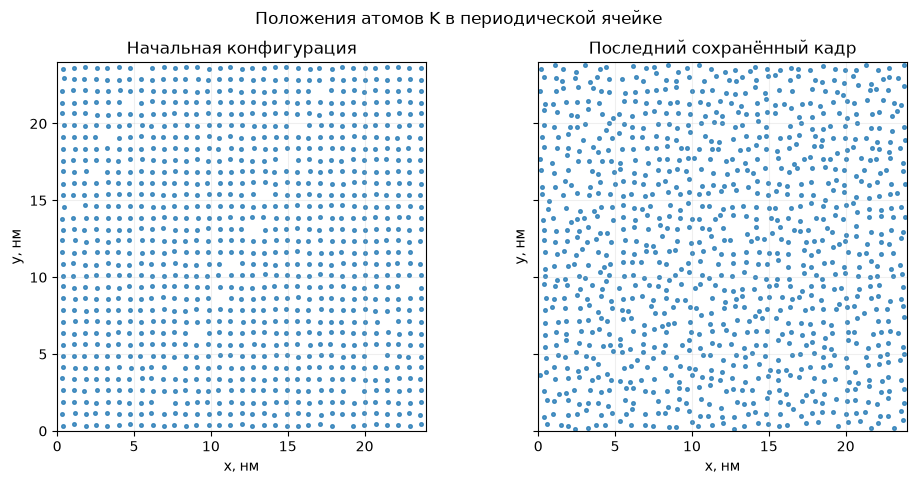

CSV и GIF сохранены в: output/notebooks/task1_periodic


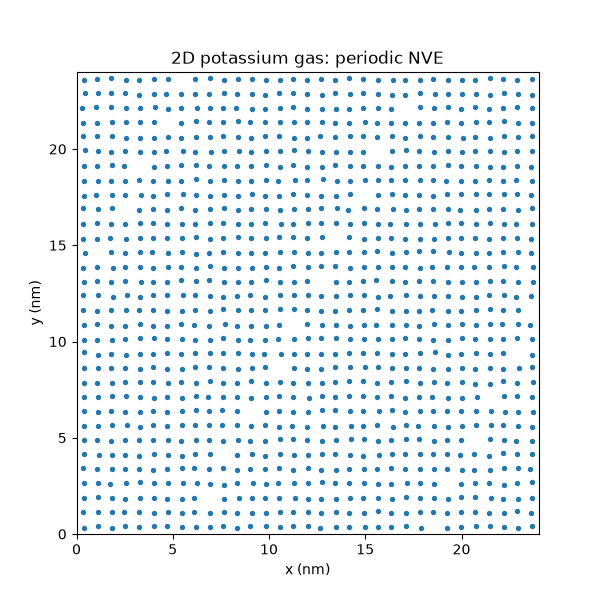

**Расчётная сводка (DEMO, seed 7):** N=1035; длительность 0.300 пс; начальная T=1173.15 K; средняя T по ряду=1233.04 K; среднее P₂D=2.22257e-02 Н/м; условный 3D-эквивалент=2.97938e+07 Па; максимальный относительный дрейф E=1.564e-05. Средние давления и температуры относятся ко всей конечной траектории и не означают автоматически равновесие.

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharex=True, sharey=True)
for axis, frame, title in zip(axes, [frames[0], frames[-1]], ['Начальная конфигурация', 'Последний сохранённый кадр']):
    axis.scatter(frame[:, 0] * 1e9, frame[:, 1] * 1e9, s=7, alpha=0.75)
    axis.set(title=title, xlabel='x, нм', ylabel='y, нм', xlim=(0, config.box.lx * 1e9), ylim=(0, config.box.ly * 1e9), aspect='equal')
    axis.grid(alpha=0.2)
fig.suptitle('Положения атомов K в периодической ячейке'); fig.tight_layout(); plt.show()

output_dir = PROJECT_ROOT / 'output' / 'notebooks' / 'task1_periodic'
output_dir.mkdir(parents=True, exist_ok=True)
columns = np.column_stack([history[key] for key in history])
np.savetxt(output_dir / 'timeseries.csv', columns, delimiter=',', header=','.join(history), comments='')
save_task1_animation(frames, config.box.lx, output_dir / 'trajectory.gif')
print(f'CSV и GIF сохранены в: {output_dir.relative_to(PROJECT_ROOT)}')
display(Image(filename=str(output_dir / 'trajectory.gif')))
display(Markdown(f'**Расчётная сводка ({MODE}, seed {SEED}):** N={config.n_particles}; длительность {N_STEPS * config.dt * 1e12:.3f} пс; начальная T={history["temperature"][0]:.2f} K; средняя T по ряду={np.mean(history["temperature"]):.2f} K; среднее P₂D={np.mean(history["pressure_2d"]):.5e} Н/м; условный 3D-эквивалент={np.mean(history["pressure_2d"]) / LAYER_THICKNESS:.5e} Па; максимальный относительный дрейф E={max_drift:.3e}. Средние давления и температуры относятся ко всей конечной траектории и не означают автоматически равновесие.'))

## 7. Вывод по расчёту

Рассчитанная численная сводка выведена непосредственно над этим разделом из выполненной траектории. Укажите в отчёте режим, длительность и seed. DEMO проверяет только работу расчётной цепочки; FULL даёт более длинный ряд, но само по себе увеличение длины не заменяет отдельную проверку стационарности, выполненную в работе 02. В NVE полная энергия должна сохраняться с численной точностью, а мгновенные T и P могут флуктуировать.

## Возможные вопросы преподавателя

1. **Почему применён LJ-потенциал?** Это прозрачная парная модель короткодействующего отталкивания и дисперсионного притяжения; для металла это упрощение, а не полный электронный потенциал.
2. **Что означает $\sigma$?** Расстояние, где несдвинутый LJ-потенциал равен нулю; минимум находится при $2^{1/6}\sigma$.
3. **Зачем cutoff?** Ограничить радиус взаимодействия и ускорить расчёт; сдвиг энергии приводит её к нулю на cutoff.
4. **Как работает minimum image?** Для каждой периодической оси выбирается ближайший образ частицы, чтобы учесть взаимодействие через границу.
5. **Что делает `run_nve`?** Инициализирует движок, многократно применяет шаг Velocity Verlet и возвращает словарь временных наблюдений и координаты кадров.
6. **Зачем в `run_nve` передавать `sample_interval` и `frame_interval`?** Они определяют частоту сохранения графиковых величин и координат кадров, а не физический шаг интегратора.
7. **Почему давление в 2D — Н/м?** В двумерном вириальном выражении энергия делится на площадь: Дж/м² = Н/м.
8. **Почему температура может отличаться от заданной?** Задано начальное распределение скоростей; в NVE термостат не поддерживает температуру, а энергия обменивается между кинетической и потенциальной формами.
9. **Как проверить сохранение энергии?** Построить $(E(t)-E_0)/|E_0|$ и проверить малые ограниченные отклонения при уменьшении шага и сравнении траекторий.
10. **Является ли среднее DEMO равновесным давлением?** Нет. Короткий запуск предназначен для технической проверки; нужно отдельно обнаружить переходный участок и проверить корреляции.